# RM4 · Fourier transform properties and what they mean in MRI

**Part:** Math refresher · **Reading time:** ~30 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [RM3 Continuous FT and DFT](RM3_Continuous_FT_and_DFT.ipynb)

In MRI you rarely compute Fourier integrals by hand. Instead you reason with a handful of **properties**:
"the object moved → linear phase in k-space", "I sampled less k-space → the image is blurred by a
sinc", "the object is real → half of k-space is redundant". Each property below comes with its formula,
a sentence in words, a small numpy check, and its MRI interpretation. Together with the pairs in
[RM5](RM5_Fourier_Pairs_and_Sampling.ipynb) this is the toolbox for the whole image-formation part of the series.

## Learning goals

1. State linearity, shift, modulation, scaling, convolution, conjugate symmetry, Parseval and derivative properties in the MRI convention.
2. Verify each one numerically with `mt.fftc`.
3. Translate each into an MRI statement: object position ↔ k-space phase, slice offset ↔ RF modulation, pixel size ↔ k-space extent, k-space weighting ↔ point spread function, real objects ↔ partial Fourier, noise ↔ Parseval.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x$, $k$ | position, spatial frequency | m, m⁻¹ | |
| $f(x),\,g(x)$ and $F(k),\,G(k)$ | two functions and their Fourier transforms | | here $G$ is a transform, **not** a gradient |
| $\mathcal F\{\cdot\}$ | Fourier transform, $F(k)=\int f(x)e^{-i2\pi kx}dx$ | | [RM3](RM3_Continuous_FT_and_DFT.ipynb) |
| $\alpha,\ \beta$ | constant (complex) weights | – | |
| $x_0$ | a shift in position | m | |
| $k_0$ | a shift in spatial frequency | m⁻¹ | |
| $a$ | scaling factor | – | |
| $*$ | convolution (as an operator between functions) | | as superscript $^*$: complex conjugate |
| $h(x)$, $H(k)$ | point spread function (PSF) and its transform (k-space weighting) | | |
| $t$, $f_{off}$ | time; RF frequency offset | s, Hz | |
| $b_1(t)$ | RF pulse envelope (rotating frame) | T | |
| $G_z$, $z_{off}$ | slice-select gradient; slice position offset | T/m, m | 10 mT/m; cm |
| $\bar\gamma$ | gyromagnetic ratio | Hz/T | 42.58 MHz/T |
| $\sigma_n$ | noise standard deviation | a.u. | |
| $N$, $\Delta x$, $\Delta k$ | samples, sample spacings | –, m, m⁻¹ | $\Delta x\Delta k=1/N$ |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

# Common grids (see RM3): 512 samples of 0.5 mm -> FOV = 25.6 cm
N, dx = 512, 0.5e-3
x = (np.arange(N) - N // 2) * dx            # position [m]
dk = 1 / (N * dx)
k = (np.arange(N) - N // 2) * dk            # spatial frequency [1/m]

def FT(f):
    """Numerical continuous FT on the centred grids: F(k_m) ~ dx * sum f(x_n) exp(-i 2 pi k_m x_n)."""
    return dx * np.sqrt(N) * mt.fftc(f)

def IFT(F):
    """Numerical inverse continuous FT: f(x_n) ~ dk * sum F(k_m) exp(+i 2 pi k_m x_n)."""
    return dk * np.sqrt(N) * mt.ifftc(F)

## Summary table

| property | function | transform | MRI meaning |
|---|---|---|---|
| linearity | $\alpha f+\beta g$ | $\alpha F+\beta G$ | signals of all voxels/tissues simply add |
| shift | $f(x-x_0)$ | $e^{-i2\pi kx_0}F(k)$ | object position ↔ linear phase in k-space |
| modulation | $e^{+i2\pi k_0x}f(x)$ | $F(k-k_0)$ | phase ramp (gradient) moves you in k-space; frequency offset moves the slice |
| scaling | $f(x/a)$ | $\lvert a\rvert F(ak)$ | small pixels ↔ large $k_{max}$; short RF pulse ↔ wide bandwidth |
| convolution | $f*g$ | $FG$ | k-space weighting = image blurring by the PSF |
| product | $fg$ | $F*G$ | |
| conjugate symmetry | $f$ real | $F(-k)=F^*(k)$ | half of k-space redundant → partial Fourier |
| Parseval | $\int\lvert f\rvert^2dx$ | $=\int\lvert F\rvert^2dk$ | energy/noise is the same in both domains |
| derivative | $df/dx$ | $i2\pi k\,F(k)$ | edges live at high $k$ |
| duality | $F(x)$ | $f(-k)$ | every pair works in both directions |

## 1. Linearity

$$\mathcal F\{\alpha f+\beta g\}=\alpha F+\beta G.$$

In words: the transform of a sum is the sum of the transforms. Where: $\alpha,\beta$ = constants.

**MRI:** the received signal is the sum of the signals from every voxel. Each voxel's contribution can be analysed alone and added afterwards —
which is what lets us describe the whole imaging chain by its response to a single point (the PSF, below).

In [2]:
f = mt.rect(x / 0.04); g = np.exp(-np.pi * (x / 0.01) ** 2)
print("linearity holds:", np.allclose(FT(2 * f - 3j * g), 2 * FT(f) - 3j * FT(g)))

linearity holds: True


## 2. Shift theorem: shift ↔ linear phase

$$\mathcal F\{f(x-x_0)\}=e^{-i2\pi kx_0}\,F(k).$$

In words: moving an object by $x_0$ does not change $|F(k)|$ at all; it only adds a phase that grows **linearly** in $k$ with slope $-2\pi x_0$ (rad per m⁻¹).
The phase wraps once every $\Delta k=1/x_0$. Where: $x_0$ = shift [m].

<details><summary><b>📐 Derivation (optional)</b></summary>

Substitute $u=x-x_0$: $\int f(x-x_0)e^{-i2\pi kx}dx=\int f(u)e^{-i2\pi k(u+x_0)}du=e^{-i2\pi kx_0}\int f(u)e^{-i2\pi ku}du$.

</details>

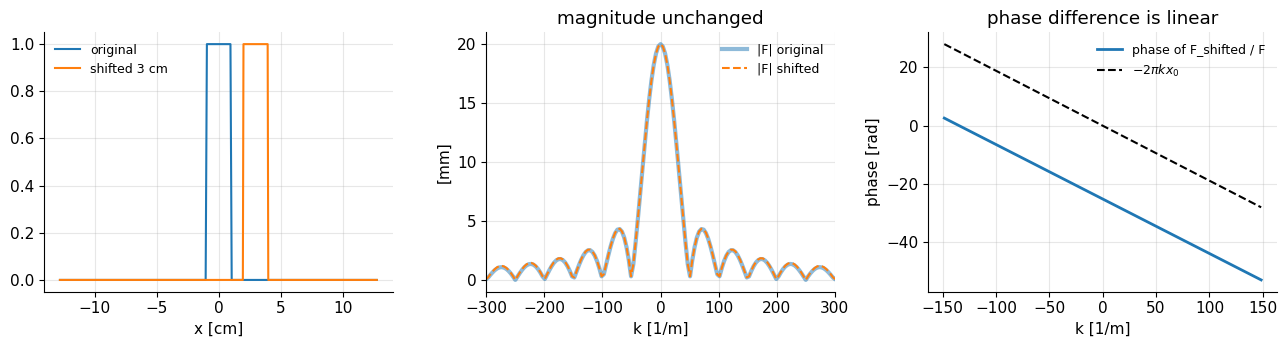

In [3]:
x0 = 0.03                                          # shift by 3 cm
f = mt.rect(x / 0.02)                              # 2 cm wide object at the centre
F, Fs = FT(f), FT(mt.rect((x - x0) / 0.02))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(x * 100, f, label="original"); ax[0].plot(x * 100, mt.rect((x - x0) / 0.02), label="shifted 3 cm")
ax[0].set_xlabel("x [cm]"); ax[0].legend(fontsize=9)
ax[1].plot(k, np.abs(F) * 1e3, lw=3, alpha=0.5, label="|F| original"); ax[1].plot(k, np.abs(Fs) * 1e3, "--", label="|F| shifted")
ax[1].set_xlim(-300, 300); ax[1].set_xlabel("k [1/m]"); ax[1].set_ylabel("[mm]"); ax[1].legend(fontsize=9); ax[1].set_title("magnitude unchanged")
sel = np.abs(k) < 150
ax[2].plot(k[sel], np.unwrap(np.angle(Fs[sel] / F[sel])), lw=2, label="phase of F_shifted / F")
ax[2].plot(k[sel], -2 * np.pi * k[sel] * x0, "k--", label=r"$-2\pi k x_0$")
ax[2].set_xlabel("k [1/m]"); ax[2].set_ylabel("phase [rad]"); ax[2].legend(fontsize=9); ax[2].set_title("phase difference is linear")
plt.tight_layout(); plt.show()

The two magnitudes coincide exactly; all the position information is in the linear phase ramp $-2\pi kx_0$.

**MRI:** (1) An object off the centre of the FOV has the same k-space magnitude as a centred one, with a linear phase across k-space. (2) Conversely, multiplying acquired k-space data
by a linear phase **moves the reconstructed image** — this is how scanners shift the FOV centre (e.g. along the readout direction) without moving the patient, and how
the "FOV offset" of a phase-encoding direction is implemented.

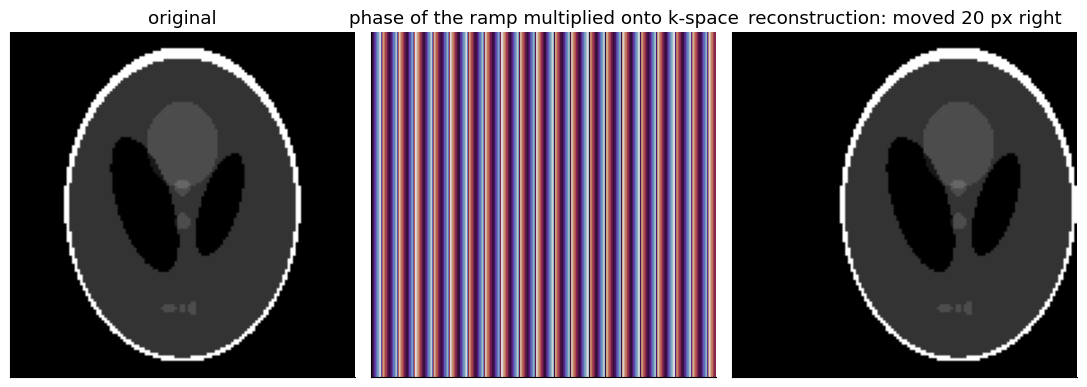

In [4]:
# 2D quick look: shift an image by multiplying its k-space by a linear phase
img = mt.shepp_logan(128)
K = mt.fft2c(img)
ky, kx = np.meshgrid(np.arange(128) - 64, np.arange(128) - 64, indexing="ij")   # in cycles per FOV
shift_px = (0, 20)                                                                # (rows, cols) in pixels
ramp = np.exp(-1j * 2 * np.pi * (ky * shift_px[0] + kx * shift_px[1]) / 128)    # linear phase, 20 cycles across k_x
K_shift = K * ramp
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
mt.show_image(img, ax=ax[0], title="original")
mt.show_image(np.angle(ramp), ax=ax[1], title="phase of the ramp multiplied onto k-space", cmap="twilight")
mt.show_image(mt.ifft2c(K_shift), ax=ax[2], title="reconstruction: moved 20 px right")
plt.tight_layout(); plt.show()

A phase ramp along $k_x$ with 20 cycles across k-space moves the image by 20 pixels; parts pushed past the right edge reappear on the left because the DFT is periodic.

## 3. Modulation: linear phase ↔ shift in frequency

The dual of the shift theorem:

$$\mathcal F\{e^{+i2\pi k_0x}f(x)\}=F(k-k_0).$$

In words: multiplying by a complex wave with $k_0$ cycles/m moves the whole spectrum by $k_0$. Where: $k_0$ = frequency shift [m⁻¹].
The same statement holds in time: multiplying a signal by $e^{+i2\pi f_{off}t}$ shifts its spectrum by $f_{off}$ [Hz].

**MRI, two big uses.**

- **Gradients move you through k-space.** A gradient gives each position an extra phase that is linear in $x$, i.e. it multiplies $m(x)$ by $e^{-i2\pi k x}$. By this theorem that is a shift in k-space: the measured signal is the object's spectrum evaluated at a moving point $k(t)$ ([F2 K-space](../pass2_deep_dive/F2_K-space.ipynb)).
- **Slice offset.** With a slice-select gradient $G_z$, position maps to frequency, $f=\bar\gamma G_zz$. Modulating the RF envelope, $b_1(t)\to b_1(t)e^{i2\pi f_{off}t}$, shifts the excitation band by $f_{off}$, i.e. moves the slice by $z_{off}=f_{off}/(\bar\gamma G_z)$ (the sign depends on conventions; see [E2 Slice selection](../pass2_deep_dive/E2_Slice_Selection.ipynb)). With $G_z=10$ mT/m, a 4.26 kHz offset moves the slice by 1 cm.

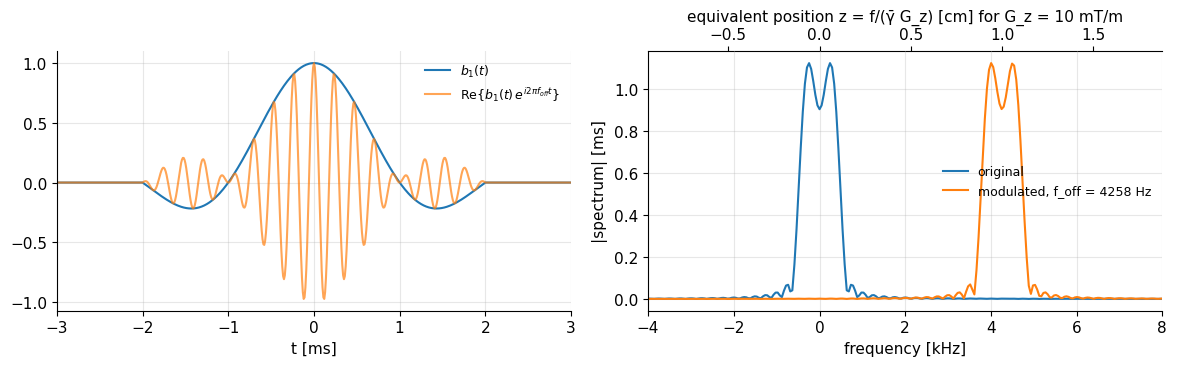

In [5]:
# RF-like example in time: a sinc pulse (4 ms, zero crossings every 1 ms -> ~1 kHz bandwidth), modulated by f_off
Nt, dt = 2048, 10e-6                                   # 10 us samples, 20.48 ms window
t = (np.arange(Nt) - Nt // 2) * dt                     # [s]
fax = (np.arange(Nt) - Nt // 2) / (Nt * dt)            # [Hz]
pulse = np.sinc(t / 1e-3) * mt.rect(t / 4e-3)          # envelope, normalized
f_off = 4258.0                                         # [Hz]
FTt = lambda s: dt * np.sqrt(Nt) * mt.fftc(s)          # continuous FT in time (RM3)

G_z = 10e-3                                            # slice-select gradient [T/m]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(t * 1e3, pulse, label=r"$b_1(t)$")
ax[0].plot(t * 1e3, (pulse * np.exp(1j * 2 * np.pi * f_off * t)).real, alpha=0.7, label=r"Re$\{b_1(t)\,e^{i2\pi f_{off}t}\}$")
ax[0].set_xlim(-3, 3); ax[0].set_xlabel("t [ms]"); ax[0].legend(fontsize=9)
for s, lab in [(pulse, "original"), (pulse * np.exp(1j * 2 * np.pi * f_off * t), f"modulated, f_off = {f_off:g} Hz")]:
    ax[1].plot(fax / 1e3, np.abs(FTt(s)) * 1e3, label=lab)
top = ax[1].secondary_xaxis("top", functions=(lambda fk: fk * 1e3 / (mt.GAMMA_BAR * G_z) * 100, lambda zc: zc / 100 * mt.GAMMA_BAR * G_z / 1e3))
top.set_xlabel("equivalent position z = f/(γ̄ G_z) [cm] for G_z = 10 mT/m")
ax[1].set_xlim(-4, 8); ax[1].set_xlabel("frequency [kHz]"); ax[1].set_ylabel("|spectrum| [ms]"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

The spectrum keeps its shape and moves by exactly 4.258 kHz, which in a 10 mT/m slice gradient is a 1 cm slice shift.

## 4. Scaling: wide ↔ narrow

$$\mathcal F\{f(x/a)\}=|a|\,F(ak).$$

In words: stretching a function by a factor $a$ squeezes its transform by the same factor (and scales its height so the area relations stay consistent). Where: $a$ = dimensionless stretch factor.

**MRI:** finer pixels (narrower image-domain features) require sampling farther out in k-space, $\Delta x=1/(2k_{max})$; a larger FOV requires finer k-space steps, $\Delta k=1/FOV$.
For RF pulses, halving the duration doubles the bandwidth (the **time–bandwidth product** is fixed by the pulse shape) — and for a given gradient doubles the slice thickness.

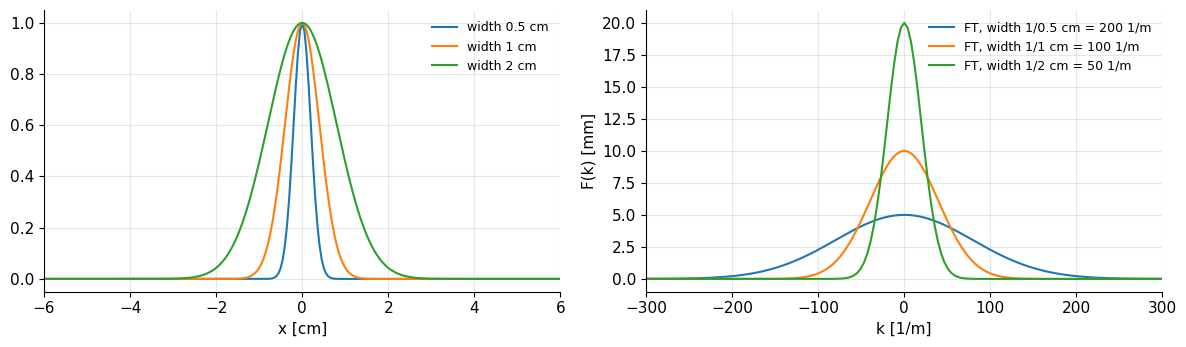

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a in [1, 2, 4]:
    w = 0.005 * a                                   # Gaussian width 0.5, 1, 2 cm
    f = np.exp(-np.pi * (x / w) ** 2)
    ax[0].plot(x * 100, f, label=f"width {w*100:g} cm")
    ax[1].plot(k, FT(f).real * 1e3, label=f"FT, width 1/{w*100:g} cm = {1/w:.0f} 1/m")
ax[0].set_xlim(-6, 6); ax[0].set_xlabel("x [cm]"); ax[0].legend(fontsize=9)
ax[1].set_xlim(-300, 300); ax[1].set_xlabel("k [1/m]"); ax[1].set_ylabel("F(k) [mm]"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

Each doubling of the width halves the width of the transform and doubles its peak (which equals the area of $f$).

## 5. Convolution theorem: multiplication ↔ convolution

The **convolution** of $f$ and $h$ is

$$(f*h)(x)=\int_{-\infty}^{\infty}f(x')\,h(x-x')\,dx'.$$

In words: place a copy of $h$ at every point $x'$, weight it by $f(x')$, and add up — "smear $f$ with the kernel $h$".
Where: $x'$ = dummy integration variable [m]. (Animation below: a box convolved with itself gives a triangle.)

![Convolution of a box with itself (Wikipedia, CC BY-SA)](../images/Convolution_of_box_signal_with_itself2.gif)

The **convolution theorem**:

$$\mathcal F\{f*h\}=F(k)\,H(k),\qquad \mathcal F\{f\cdot h\}=F*H.$$

In words: convolving in one domain = multiplying in the other. This is exactly your low-pass filter: multiplying the spectrum by a filter $H(k)$ that is small at high $k$ is the same as
blurring the signal with the kernel $h(x)=\mathcal F^{-1}\{H\}$.

**MRI — the point spread function.** Everything that weights k-space — the finite extent of sampling, $T_2^*$ decay during the readout, deliberate filters — multiplies
the true k-space $M(k)$ by some $H(k)$. Then the image is the true object convolved with the **point spread function** $h(x)$:

$$\hat m(x)=\mathcal F^{-1}\{M(k)\,H(k)\}=m(x)*h(x).$$

In words: every point of the object is replaced by a copy of the PSF. Where: $m(x)$ = true object, $\hat m$ = reconstructed image, $M(k)$ = its k-space (here $M$ is k-space data, not magnetization). Details: [I1 PSF analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb).

k-space multiplication == convolution with PSF: True
PSF integral = 1.000 (a filter with H(0) = 1 preserves the mean)


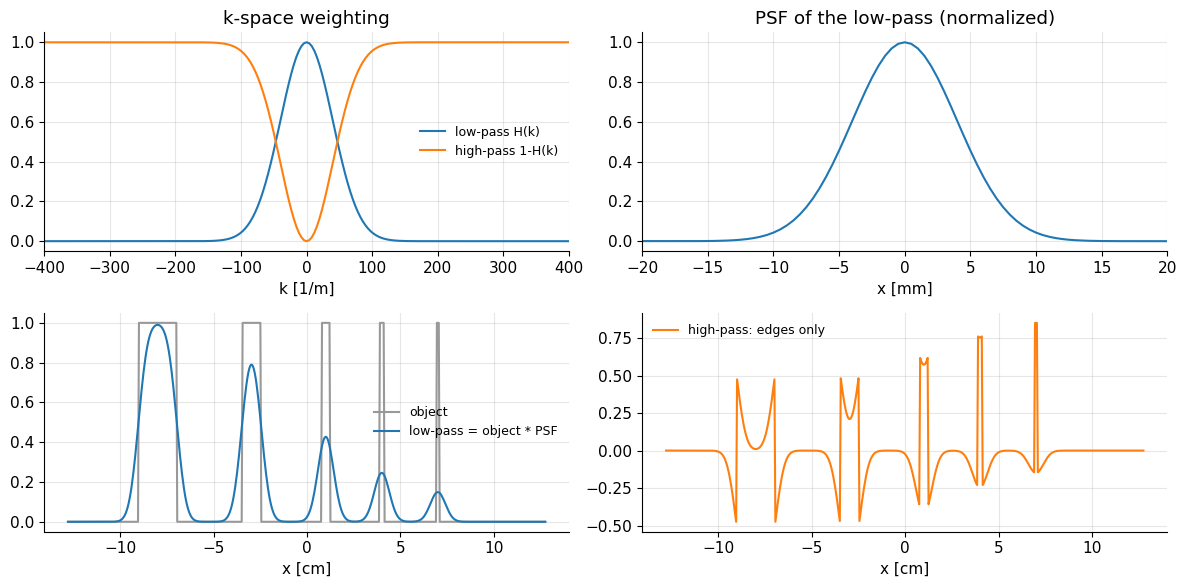

In [7]:
# object: bars of different widths (a 1D "resolution phantom")
obj = sum(mt.rect((x - c) / w) for c, w in [(-0.08, 0.02), (-0.03, 0.01), (0.01, 0.005), (0.04, 0.0025), (0.07, 0.00125)])
H_lp = np.exp(-np.pi * (k / 100.0) ** 2)            # Gaussian low-pass in k-space, width 100 1/m
H_hp = 1 - H_lp                                      # complementary high-pass
img_lp = IFT(FT(obj) * H_lp).real
img_hp = IFT(FT(obj) * H_hp).real

# check: the same as convolving directly with the PSF h = IFT(H), using circular convolution like the DFT
h_lp = IFT(H_lp).real                               # [1/m]; analytic: 100 exp(-pi (100 x)^2)
conv = dx * np.real(np.fft.ifft(np.fft.fft(np.fft.ifftshift(h_lp)) * np.fft.fft(obj)))
print("k-space multiplication == convolution with PSF:", np.allclose(conv, img_lp))
print(f"PSF integral = {np.sum(h_lp)*dx:.3f} (a filter with H(0) = 1 preserves the mean)")

fig, ax = plt.subplots(2, 2, figsize=(12, 6))
ax[0, 0].plot(k, H_lp, label="low-pass H(k)"); ax[0, 0].plot(k, H_hp, label="high-pass 1-H(k)")
ax[0, 0].set_xlim(-400, 400); ax[0, 0].set_xlabel("k [1/m]"); ax[0, 0].legend(fontsize=9); ax[0, 0].set_title("k-space weighting")
ax[0, 1].plot(x * 1000, h_lp / h_lp.max()); ax[0, 1].set_xlim(-20, 20); ax[0, 1].set_xlabel("x [mm]"); ax[0, 1].set_title("PSF of the low-pass (normalized)")
ax[1, 0].plot(x * 100, obj, color="0.6", label="object"); ax[1, 0].plot(x * 100, img_lp, label="low-pass = object * PSF")
ax[1, 0].set_xlabel("x [cm]"); ax[1, 0].legend(fontsize=9)
ax[1, 1].plot(x * 100, img_hp, color="C1", label="high-pass: edges only"); ax[1, 1].set_xlabel("x [cm]"); ax[1, 1].legend(fontsize=9)
plt.tight_layout(); plt.show()

Multiplying in k-space and convolving with the PSF give identical results; the low-pass keeps the wide bars and blurs the narrow ones together, the high-pass keeps only the edges.

> **⚠️ Common confusion:** the DFT implements **circular** convolution: a kernel that hangs over one edge wraps around to the other side. For filtering images that is usually
> harmless (the edges of the FOV are dark); when it matters, zero-pad first.

## 6. Conjugate (Hermitian) symmetry: real signals

$$f(x)\ \text{real}\quad\Longleftrightarrow\quad F(-k)=F^*(k).$$

In words: for a real function, the value at $-k$ is the complex conjugate of the value at $+k$ — the magnitude is symmetric and the phase antisymmetric, so **half of the transform is redundant**.
Where: $^*$ = complex conjugate (not convolution).

<details><summary><b>📐 Derivation (optional)</b></summary>

$F^*(k)=\left(\int f(x)e^{-i2\pi kx}dx\right)^*=\int f^*(x)e^{+i2\pi kx}dx$. If $f=f^*$ this equals $\int f(x)e^{-i2\pi(-k)x}dx=F(-k)$.

</details>

**MRI — partial Fourier.** If the image $m(x)$ were real, we could acquire only a bit more than half of k-space and fill the rest with $F(-k)=F^*(k)$, saving up to ~40 % scan time
(phase direction) or echo time (readout direction). Real MRI images are *not* real: off-resonance, coil sensitivities and RF give a (usually smooth) phase. Practical methods (homodyne, POCS) first estimate that phase
from a small fully-sampled centre of k-space ([H3 Accelerated imaging](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)). The demo shows both cases.

real object: F(-k) == conj(F(k)): True
real object               : max error = 4.44e-16
object with smooth phase  : max error = 1.62e+00


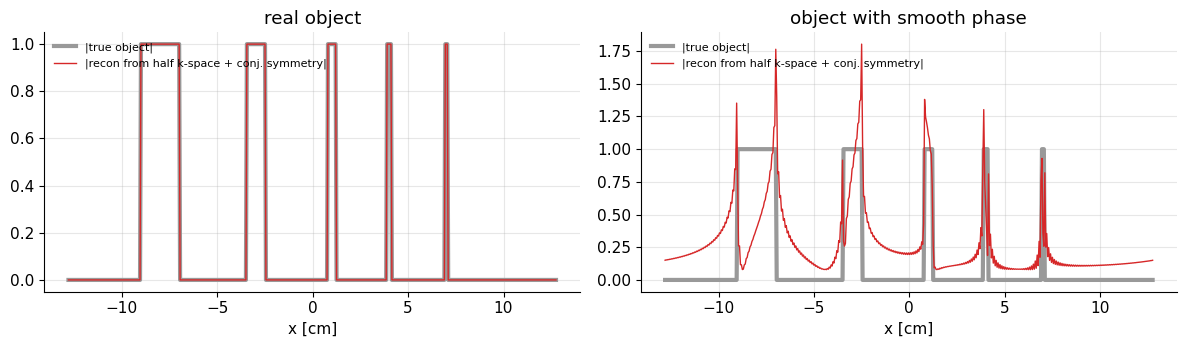

In [8]:
def conj_fill(F):
    """Keep k >= 0 (indices N//2..N-1) plus the lone k = -N/2 sample; fill k < 0 by F(-k) = F*(k)."""
    G = np.zeros_like(F)
    G[N // 2:] = F[N // 2:]
    G[0] = F[0]
    G[1:N // 2] = np.conj(F[N // 2 + 1:][::-1])      # index m (k<0) <- conj of index N-m (k>0)
    return G

obj_real = obj * 1.0
phase = 1.2 * np.sin(2 * np.pi * x / 0.25)           # smooth image phase [rad], as from B0 inhomogeneity
obj_cplx = obj * np.exp(1j * phase)

F = FT(obj_real)
print("real object: F(-k) == conj(F(k)):", np.allclose(F[1:], np.conj(F[1:][::-1])))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a_, o, name in [(ax[0], obj_real, "real object"), (ax[1], obj_cplx, "object with smooth phase")]:
    rec = IFT(conj_fill(FT(o)))
    a_.plot(x * 100, np.abs(o), color="0.6", lw=3, label="|true object|")
    a_.plot(x * 100, np.abs(rec), "C3", lw=1, label="|recon from half k-space + conj. symmetry|")
    a_.set_xlabel("x [cm]"); a_.set_title(name); a_.legend(fontsize=8, loc="upper left")
    print(f"{name:26s}: max error = {np.max(np.abs(rec - o)):.2e}")
plt.tight_layout(); plt.show()

For a real object, half of k-space reconstructs it perfectly; with a phase of only ±1.2 rad the naive conjugate fill fails badly — hence the phase-corrected methods used on scanners.

## 7. Parseval's (Plancherel's) theorem: energy and noise

$$\int|f(x)|^2dx=\int|F(k)|^2dk,\qquad\text{discrete, unitary FFT: }\sum_n|f_n|^2=\sum_m|F_m|^2.$$

In words: the total "energy" is the same in both domains. Where: with `norm="ortho"` (as in `mt.fftc`) the DFT is a unitary matrix, so sums of squares are preserved exactly.

**MRI:** (1) Independent Gaussian noise of standard deviation $\sigma_n$ on every k-space sample becomes independent noise of the *same* $\sigma_n$ on every pixel (unitary transform),
which is the starting point of every SNR calculation ([G2 SNR](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)). (2) Most of an image's energy sits near the k-space centre, which is why
low-resolution scans already look "mostly right".

In [9]:
rng = np.random.default_rng(0)
img = mt.shepp_logan(256)
K = mt.fft2c(img)
print(f"sum |img|^2 = {np.sum(np.abs(img)**2):.4f},   sum |K|^2 = {np.sum(np.abs(K)**2):.4f}")
kr = np.hypot(*np.meshgrid(np.arange(256) - 128, np.arange(256) - 128))
for r in [8, 32]:
    print(f"|k| < {r:2d} cycles/FOV: {np.mean(kr < r)*100:4.1f} % of the samples hold "
          f"{np.sum(np.abs(K[kr < r])**2) / np.sum(np.abs(K)**2)*100:.0f} % of the energy")

sigma = 0.05
noise_k = mt.add_complex_noise(np.zeros((256, 256)), sigma, rng)    # noise only, in k-space
noise_img = mt.ifft2c(noise_k)
print(f"noise std in k-space (real part) = {noise_k.real.std():.4f},  in the image (real part) = {noise_img.real.std():.4f}")

sum |img|^2 = 3974.0800,   sum |K|^2 = 3974.0800
|k| <  8 cycles/FOV:  0.3 % of the samples hold 58 % of the energy
|k| < 32 cycles/FOV:  4.9 % of the samples hold 88 % of the energy
noise std in k-space (real part) = 0.0500,  in the image (real part) = 0.0499


Energy is preserved exactly; more than half of it sits in the central 0.3 % of k-space samples (and ~88 % in the central 5 %); and noise keeps its standard deviation through the unitary FFT.

## 8. Derivative: edges live at high $k$

$$\mathcal F\left\{\frac{df}{dx}\right\}=i2\pi k\,F(k).$$

In words: differentiating multiplies the spectrum by $i2\pi k$ — it amplifies high frequencies in proportion to $k$. A derivative is an extreme high-pass filter.
Where: $k$ [m⁻¹]; the result has units of $F$ per metre.

**MRI:** sharp edges contain strong high-$k$ components (the spectrum of a step decays only like $1/k$), so resolving edges requires large $k_{max}$; filters that weight up high $k$ sharpen
but also amplify noise. The factor $|k|$ also appears as the "ramp filter"/density compensation in radial reconstruction ([J5 Advanced reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb)).

derivative via FFT matches analytic: True


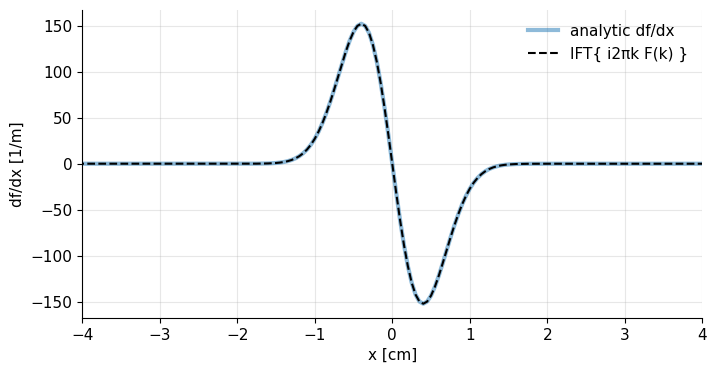

In [10]:
w = 0.01
f = np.exp(-np.pi * (x / w) ** 2)
df_analytic = -2 * np.pi * x / w**2 * f
df_fourier = IFT(1j * 2 * np.pi * k * FT(f)).real
print("derivative via FFT matches analytic:", np.allclose(df_fourier, df_analytic, atol=1e-6 * np.abs(df_analytic).max()))
plt.plot(x * 100, df_analytic, lw=3, alpha=0.5, label="analytic df/dx")
plt.plot(x * 100, df_fourier, "k--", label=r"IFT{ i2πk F(k) }")
plt.xlim(-4, 4); plt.xlabel("x [cm]"); plt.ylabel("df/dx [1/m]"); plt.legend(); plt.show()

Multiplying by $i2\pi k$ in k-space produces the derivative exactly.

## Where this shows up in MRI

| Property | Where it is used |
|---|---|
| linearity, convolution, PSF | [I1 PSF analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb), [G3 Cartesian image characteristics](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb), [F3 Image reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) |
| shift / modulation | [F1 Spatial encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb), [F2 K-space](../pass2_deep_dive/F2_K-space.ipynb), [E2 Slice selection](../pass2_deep_dive/E2_Slice_Selection.ipynb), [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb) (chemical-shift displacement) |
| scaling | [G1 FOV and resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb), [E1 RF pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb) (time–bandwidth product) |
| conjugate symmetry | [H3 Accelerated imaging](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) (partial Fourier) |
| Parseval | [G2 Signal-to-noise ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb), [J4 Advanced SNR](../pass2_deep_dive/J4_Advanced_SNR.ipynb) |
| derivative | [J5 Advanced reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |

Compact formula sheet: [MRI math concepts](../reference/MRI_Math_Concepts.ipynb).

## Key takeaways

- Linearity lets us describe the whole imaging chain by its response to one point (the PSF).
- Shift ↔ linear phase: position is encoded in k-space **phase**; multiplying k-space by a phase ramp moves the image.
- Modulation ↔ frequency shift: gradients move the sampling point through k-space; an RF frequency offset moves the slice by $f_{off}/(\bar\gamma G_z)$.
- Scaling: wide ↔ narrow. Small pixels need large $k_{max}$; short RF pulses have wide bandwidths.
- Convolution theorem: any k-space weighting (finite sampling, decay, filters) blurs the image with its PSF — your low-pass filter, in MRI language.
- Real objects have Hermitian k-space; partial Fourier exploits it, but real MRI images have phase that must be estimated first.
- Parseval: energy and white noise are preserved by the unitary FFT (`norm="ortho"`).

## Check your understanding

1. An object moves 1 cm along $x$ between two scans. What changes in its k-space data, and at which $\Delta k$ does the phase difference wrap through $2\pi$?
<details><summary>Answer</summary>

Only the phase: it changes by $-2\pi k\cdot0.01$ m, i.e. a linear ramp that wraps every $\Delta k=1/x_0=100$ m⁻¹. Magnitudes are unchanged.

</details>

2. With $G_z=20$ mT/m, what RF frequency offset moves the slice by 2 cm?
<details><summary>Answer</summary>

$f_{off}=\bar\gamma G_zz_{off}=42.58\times10^6\cdot0.02\cdot0.02\approx17$ kHz.

</details>

3. During the readout the signal decays with $T_2^*$, i.e. k-space is multiplied by a decaying function. What does this do to the image?
<details><summary>Answer</summary>

By the convolution theorem the image is convolved with the inverse FT of that weighting (the PSF), i.e. it is blurred along the readout direction. The shorter $T_2^*$ relative to the readout duration, the wider the PSF.

</details>

4. Why does naive partial Fourier (conjugate filling) fail for real MRI data?
<details><summary>Answer</summary>

Conjugate symmetry requires a real image. MRI images have a spatially varying phase (off-resonance, coil sensitivity, RF), so $M(-k)\ne M^*(k)$. Methods like homodyne/POCS estimate the low-resolution phase first.

</details>

5. With `norm="ortho"`, k-space noise has $\sigma_n=0.05$ per sample. What is the image-domain noise standard deviation? What would it be with numpy's default `ifft` normalization?
<details><summary>Answer</summary>

0.05 (unitary transform). numpy's default `ifft` divides by $N$ (total number of samples), not $\sqrt N$, so the noise std would be $0.05/\sqrt N$ — a different scale for both signal and noise, but the same SNR.

</details>

---
*New refresher written for this adaptation of P. Larson, "Principles of MRI" (MIT License); see references below.*
*References: R. N. Bracewell, *The Fourier Transform and Its Applications* (McGraw-Hill);
A. V. Oppenheim, A. S. Willsky, *Signals and Systems* (Prentice Hall);
D. G. Nishimura, *Principles of Magnetic Resonance Imaging*;
Z.-P. Liang, P. C. Lauterbur, *Principles of Magnetic Resonance Imaging: A Signal Processing Perspective* (IEEE Press);
D. C. Noll, D. G. Nishimura, A. Macovski, "Homodyne detection in magnetic resonance imaging", *IEEE Trans. Med. Imaging* 10:154–163 (1991).*